# EDA – Các yếu tố liên quan tới việc sinh viên bỏ học 

Dữ liệu: 3.400 sinh viên năm nhất (`students.csv`), nhãn `dropout = 1 − RETURNED_2ND_YR`.

Mỗi biểu đồ = tỉ lệ bỏ học theo nhóm, kèm số sinh viên mỗi nhóm (`n`) và đường đứt nét = tỉ lệ chung.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "ml" / "src").exists() and ROOT != ROOT.parent:   # tìm thư mục gốc repo
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "ml" / "src"))
from features import build_features  # noqa: E402

DATA = ROOT / "ml" / "data"
FIG = ROOT / "ml" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(DATA / "students.csv")
raw.columns = [c.strip().replace(" ", "_") for c in raw.columns]
mf = pd.read_csv(DATA / "major_faculty.csv")

feat = build_features(raw, mf)
df = feat.join(raw[["FIRST_TERM", "FATHER_HI_EDU_DESC", "MOTHER_HI_EDU_DESC", "FATHER_HI_EDU_CD",
                    "MOTHER_HI_EDU_CD"]])
df = df.merge(mf[["faculty_id", "faculty_name"]].drop_duplicates(), on="faculty_id", how="left")
df = df[df["is_synthetic"] == 0].reset_index(drop=True)

BASE = df["dropout"].mean()
print(f"{len(df):,} sinh viên thật, {int(df['dropout'].sum())} bỏ học -> tỉ lệ chung {BASE:.1%}")

3,400 sinh viên thật, 723 bỏ học -> tỉ lệ chung 21.3%


In [2]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
MAIN, LIGHT, BASE_C = "#2f6f9f", "#b8cde0", "#c0392b"
MIN_N = 30
LBL = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=0.5)   # nền trắng cho nhãn số
CONCLUSIONS = []


def vn(x, d=1):
    # Số kiểu Việt Nam: 1,3 thay cho 1.3
    return f"{x:.{d}f}".replace(".", ",")


def qgroups(s, q, d=2):
    # Chia s thành q nhóm có số SV gần bằng nhau, nhãn dạng '1,50–1,98'. Ô trống giữ NaN.
    cats, edges = pd.qcut(s, q, retbins=True, duplicates="drop")
    labels = [f"{vn(a, d)}–{vn(b, d)}" for a, b in zip(edges[:-1], edges[1:])]
    out = pd.qcut(s, q, labels=labels, duplicates="drop").astype(object)
    return out, labels


EDU_VI = {"Middle School/Junior High": "THCS", "High School": "THPT", "College/Beyond": "Cao đẳng/Đại học trở lên",
          "Graduate": "Sau đại học", "No Information": "Không có thông tin", "Other/Unknown": "Khác/Không rõ"}


def save(fig, name):
    path = FIG / name
    try:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    except OSError:                       # file đang mở ở chương trình khác (Windows khóa file)
        path = path.with_name(f"{path.stem}_moi{path.suffix}")
        fig.savefig(path, dpi=200, bbox_inches="tight")
    print("Đã lưu", path.name)


def rate_by(col, title, xlabel, fname, order=None, labels=None, horizontal=False, ax=None):
    """Tỉ lệ bỏ học theo nhóm + số SV mỗi nhóm. Trả về bảng (rate, n)."""
    g = df.groupby(col, observed=True, dropna=False)["dropout"].agg(rate="mean", n="size")
    if order is not None:
        g = g.reindex([o for o in order if o in g.index])
    names = [labels.get(i, i) if labels else i for i in g.index]
    names = ["Không có dữ liệu" if (isinstance(x, float) and np.isnan(x)) else str(x) for x in names]
    colors = [MAIN if n >= MIN_N else LIGHT for n in g["n"]]
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(8, 0.45 * len(g) + 1.6) if horizontal else (max(6, 1.1 * len(g) + 2), 4.2))
    if horizontal:
        ax.barh(names, g["rate"], color=colors)
        ax.axvline(BASE, ls="--", c=BASE_C, lw=1.2)
        ax.invert_yaxis()
        for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
            ax.text(r + 0.005, i, f"{r:.0%}  (n={n})", va="center", fontsize=8.5, bbox=LBL)
        ax.set_xlim(0, max(g["rate"].max() * 1.25, BASE * 1.3))
        ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, 0))
        ax.set(xlabel="Tỉ lệ bỏ học", ylabel=xlabel, title=title)
    else:
        ax.bar(names, g["rate"], color=colors)
        ax.axhline(BASE, ls="--", c=BASE_C, lw=1.2)
        for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
            ax.text(i, r + 0.008, f"{r:.0%}\nn={n}", ha="center", va="bottom", fontsize=8.5, bbox=LBL)
        ax.set_ylim(0, max(g["rate"].max() * 1.3, BASE * 1.4))
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, 0))
        ax.set(ylabel="Tỉ lệ bỏ học", xlabel=xlabel, title=title)
    ax.text(0.99, 0.02 if horizontal else 0.98, f"- - tỉ lệ chung {vn(BASE * 100, 1)}%", transform=ax.transAxes,
            ha="right", va="bottom" if horizontal else "top", color=BASE_C, fontsize=8.5,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1))
    if own:
        fig.tight_layout()
        save(fig, fname)
        plt.show()
    g.index = names
    return g


def conclude(no, g, topic):
    """Câu kết luận có số: nhóm cao nhất / thấp nhất (chỉ xét nhóm có ít nhất MIN_N sinh viên)."""
    ok = g[g["n"] >= MIN_N]
    hi, lo = ok["rate"].idxmax(), ok["rate"].idxmin()
    ratio = ok.loc[hi, "rate"] / max(ok.loc[lo, "rate"], 1e-9)
    s = (f"Hình {no} – {topic}: nhóm \"{hi}\" bỏ học {ok.loc[hi, 'rate']:.0%} (n={ok.loc[hi, 'n']}), "
         f"cao gấp {vn(ratio)} lần nhóm \"{lo}\" ({ok.loc[lo, 'rate']:.0%}, n={ok.loc[lo, 'n']}); "
         f"tỉ lệ chung {BASE:.0%}.")
    CONCLUSIONS.append(s)
    print(s)

## Hình 1 – Tỉ lệ bỏ học theo khóa
Kiểm tra tỉ lệ có ổn định qua các năm không (nếu ổn định, model học từ khóa cũ dùng được cho khóa sau).

Đã lưu eda_01_khoa_hoc.png


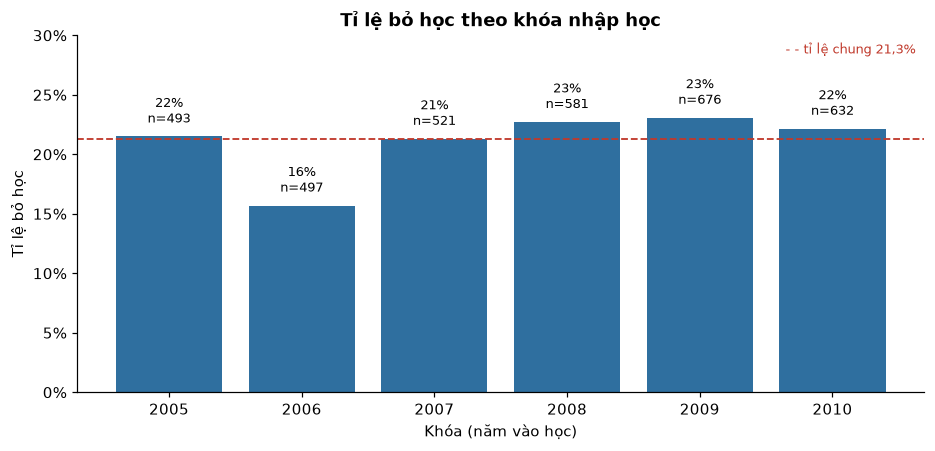

Hình 1 – Theo khóa: tỉ lệ bỏ học dao động từ 16% đến 23% qua 6 khóa, quanh mức chung 21%.


In [3]:
df["cohort"] = (df["FIRST_TERM"] // 100).astype(int)
g1 = rate_by("cohort", "Tỉ lệ bỏ học theo khóa nhập học", "Khóa (năm vào học)", "eda_01_khoa_hoc.png")
s = (f"Hình 1 – Theo khóa: tỉ lệ bỏ học dao động từ {g1['rate'].min():.0%} đến {g1['rate'].max():.0%} "
     f"qua {len(g1)} khóa, quanh mức chung {BASE:.0%}.")
CONCLUSIONS.append(s); print(s)

## Hình 2 – Theo khoa

Đã lưu eda_02_khoa.png


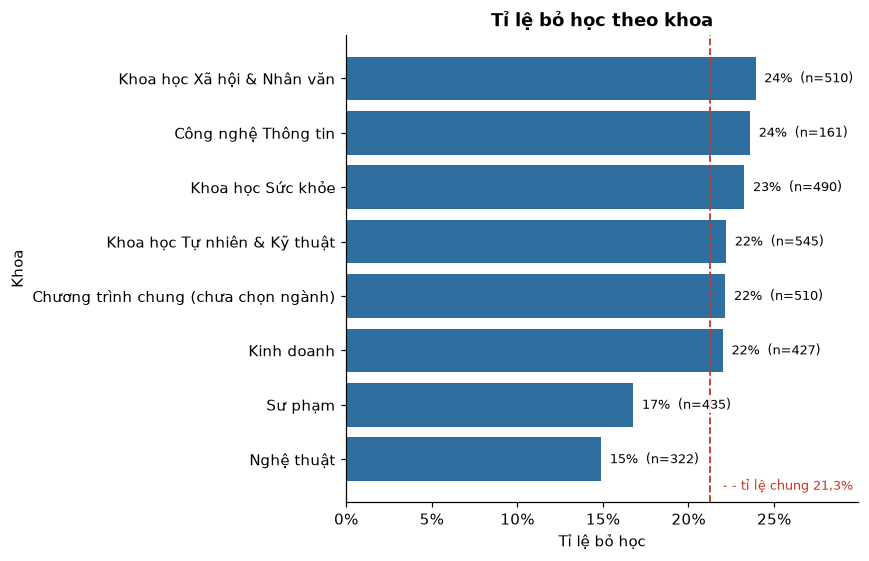

Hình 2 – Theo khoa: nhóm "Khoa học Xã hội & Nhân văn" bỏ học 24% (n=510), cao gấp 1,6 lần nhóm "Nghệ thuật" (15%, n=322); tỉ lệ chung 21%.


In [4]:
g2 = rate_by("faculty_name", "Tỉ lệ bỏ học theo khoa", "Khoa", "eda_02_khoa.png", horizontal=True,
             order=df.groupby("faculty_name")["dropout"].mean().sort_values(ascending=False).index)
conclude(2, g2, "Theo khoa")

## Hình 3 – Nơi ở và trong/ngoài bang

Đã lưu eda_03_noi_o.png


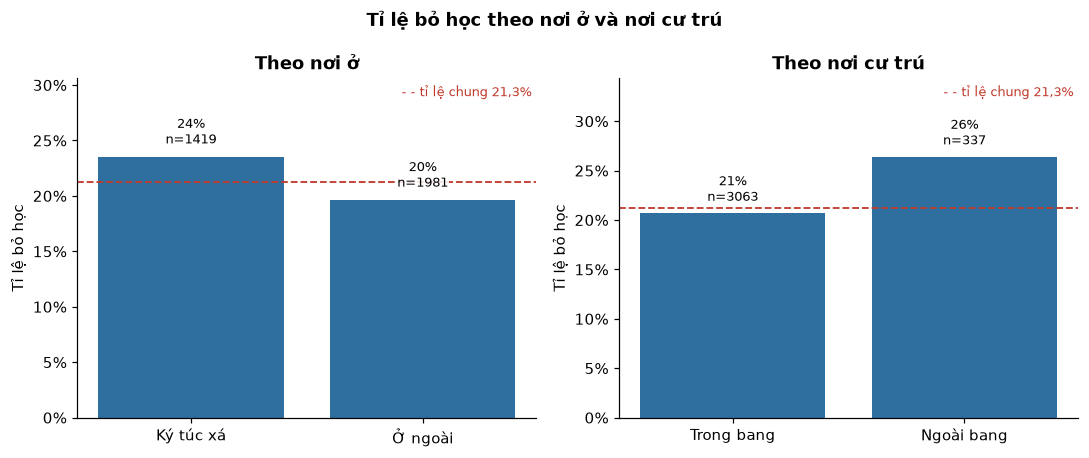

Hình 3 – Nơi ở: nhóm "Ký túc xá" bỏ học 24% (n=1419), cao gấp 1,2 lần nhóm "Ở ngoài" (20%, n=1981); tỉ lệ chung 21%.
Hình 3 – Trong/ngoài bang: nhóm "Ngoài bang" bỏ học 26% (n=337), cao gấp 1,3 lần nhóm "Trong bang" (21%, n=3063); tỉ lệ chung 21%.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
g3a = rate_by("on_campus", "Theo nơi ở", "", None, order=[1, 0], labels={1: "Ký túc xá", 0: "Ở ngoài"}, ax=axes[0])
g3b = rate_by("in_state", "Theo nơi cư trú", "", None, order=[1, 0], labels={1: "Trong bang", 0: "Ngoài bang"}, ax=axes[1])
fig.suptitle("Tỉ lệ bỏ học theo nơi ở và nơi cư trú", fontweight="bold")
fig.tight_layout(); save(fig, "eda_03_noi_o.png"); plt.show()
conclude(3, g3a, "Nơi ở")
conclude(3, g3b, "Trong/ngoài bang")

## Hình 4 – Học vấn của bố mẹ

Đã lưu eda_04_hoc_van_bo_me.png


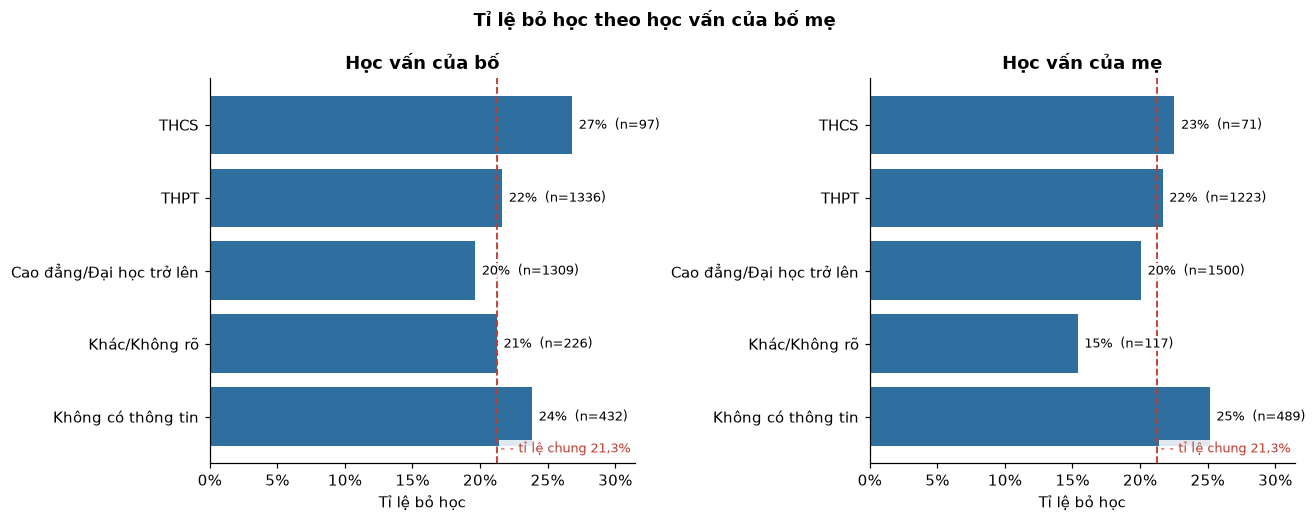

Hình 4 – Học vấn của bố: nhóm "THCS" bỏ học 27% (n=97), cao gấp 1,4 lần nhóm "Cao đẳng/Đại học trở lên" (20%, n=1309); tỉ lệ chung 21%.
Hình 4 – Học vấn của mẹ: nhóm "Không có thông tin" bỏ học 25% (n=489), cao gấp 1,6 lần nhóm "Khác/Không rõ" (15%, n=117); tỉ lệ chung 21%.


In [6]:
def edu_order(col_desc, col_cd):
    return (df.groupby(col_desc)[col_cd].mean().sort_values(na_position="last").index.tolist())


fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
g4a = rate_by("FATHER_HI_EDU_DESC", "Học vấn của bố", "", None, horizontal=True,
              order=edu_order("FATHER_HI_EDU_DESC", "FATHER_HI_EDU_CD"), labels=EDU_VI, ax=axes[0])
g4b = rate_by("MOTHER_HI_EDU_DESC", "Học vấn của mẹ", "", None, horizontal=True,
              order=edu_order("MOTHER_HI_EDU_DESC", "MOTHER_HI_EDU_CD"), labels=EDU_VI, ax=axes[1])
fig.suptitle("Tỉ lệ bỏ học theo học vấn của bố mẹ", fontweight="bold")
fig.tight_layout(); save(fig, "eda_04_hoc_van_bo_me.png"); plt.show()
conclude(4, g4a, "Học vấn của bố")
conclude(4, g4b, "Học vấn của mẹ")

## Hình 5 – GPA THPT
Chia 5 nhóm có số sinh viên gần bằng nhau (ngũ phân vị).

Đã lưu eda_05_gpa_thpt.png


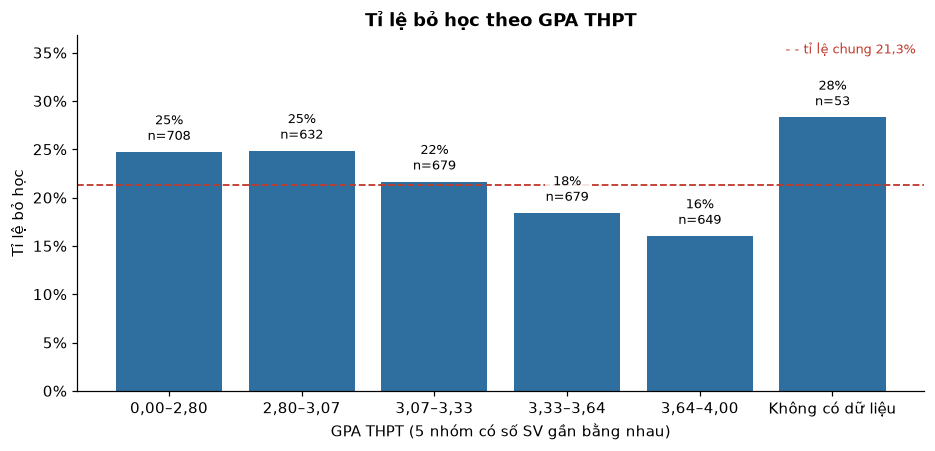

Hình 5 – GPA THPT: nhóm GPA thấp nhất (0,00–2,80) bỏ học 25%, nhóm cao nhất (3,64–4,00) chỉ 16% (chung 21%).


In [7]:
df["hs_gpa_q"], lab5 = qgroups(df["high_school_gpa"], 5)
g5 = rate_by("hs_gpa_q", "Tỉ lệ bỏ học theo GPA THPT", "GPA THPT (5 nhóm có số SV gần bằng nhau)",
             "eda_05_gpa_thpt.png", order=lab5 + [np.nan])
s = (f"Hình 5 – GPA THPT: nhóm GPA thấp nhất ({g5.index[0]}) bỏ học {g5['rate'].iloc[0]:.0%}, "
     f"nhóm cao nhất ({lab5[-1]}) chỉ {g5.loc[lab5[-1], 'rate']:.0%} (chung {BASE:.0%}).")
CONCLUSIONS.append(s); print(s)

## Hình 6 – Điểm thi đầu vào và việc thiếu điểm
15% sinh viên không có điểm kết hợp; nhóm này được tách riêng.

Đã lưu eda_06_diem_dau_vao.png


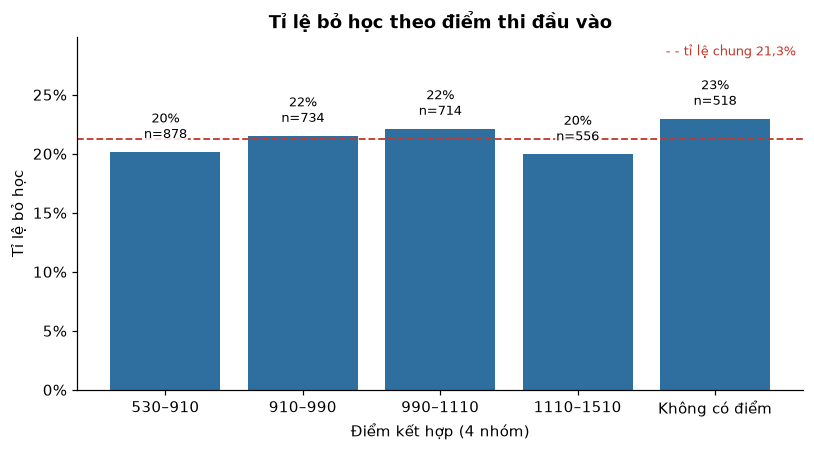

Hình 6 – Điểm đầu vào: nhóm "Không có điểm" bỏ học 23% (n=518), cao gấp 1,2 lần nhóm "1110–1510" (20%, n=556); tỉ lệ chung 21%.


In [8]:
q, lab6 = qgroups(df["entrance_comb"], 4, d=0)
df["entrance_grp"] = q.where(df["entrance_comb"].notna(), "Không có điểm")
order6 = lab6 + ["Không có điểm"]
g6 = rate_by("entrance_grp", "Tỉ lệ bỏ học theo điểm thi đầu vào", "Điểm kết hợp (4 nhóm)", "eda_06_diem_dau_vao.png",
             order=order6)
conclude(6, g6, "Điểm đầu vào")

## Hình 7 – GPA học kỳ 1

Đã lưu eda_07_gpa_hk1.png


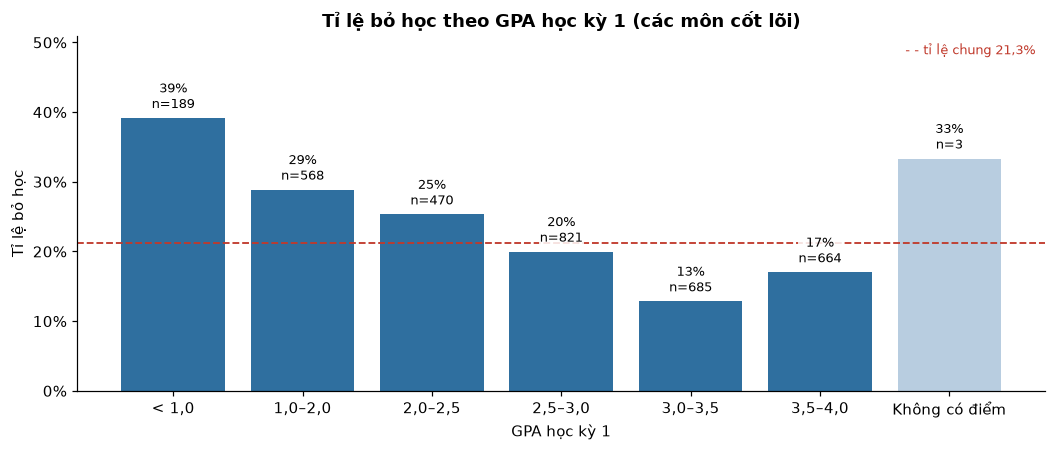

Hình 7 – GPA học kỳ 1: nhóm "< 1,0" bỏ học 39% (n=189), cao gấp 3,0 lần nhóm "3,0–3,5" (13%, n=685); tỉ lệ chung 21%.


In [9]:
bins = [-0.01, 1.0, 2.0, 2.5, 3.0, 3.5, 4.0]
names = ["< 1,0", "1,0–2,0", "2,0–2,5", "2,5–3,0", "3,0–3,5", "3,5–4,0"]
df["gpa_t1_grp"] = pd.cut(df["gpa_t1"], bins, labels=names).astype(object).where(df["gpa_t1"].notna(), "Không có điểm")
g7 = rate_by("gpa_t1_grp", "Tỉ lệ bỏ học theo GPA học kỳ 1 (các môn cốt lõi)", "GPA học kỳ 1",
             "eda_07_gpa_hk1.png", order=names + ["Không có điểm"])
conclude(7, g7, "GPA học kỳ 1")

## Hình 8 – Số môn D/F trong năm nhất

Đã lưu eda_08_mon_df.png


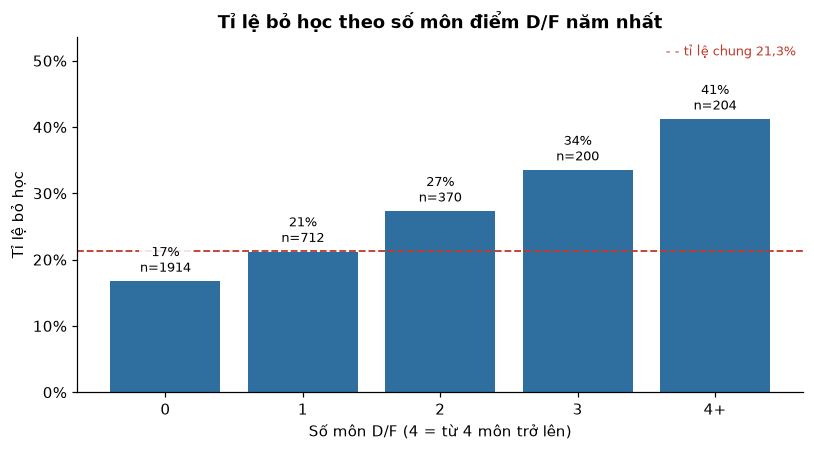

Hình 8 – Môn D/F: sinh viên không có môn D/F bỏ học 17%; từ 2 môn D/F trở lên: 33% (n=774).


In [10]:
df["n_df_year"] = (df["n_df_t1"] + df["n_df_t2"]).clip(upper=4)
g8 = rate_by("n_df_year", "Tỉ lệ bỏ học theo số môn điểm D/F năm nhất", "Số môn D/F (4 = từ 4 môn trở lên)",
             "eda_08_mon_df.png", order=[0, 1, 2, 3, 4], labels={4: "4+"})
s = (f"Hình 8 – Môn D/F: sinh viên không có môn D/F bỏ học {g8['rate'].iloc[0]:.0%}; "
     f"từ 2 môn D/F trở lên: {df.loc[df['n_df_year'] >= 2, 'dropout'].mean():.0%} "
     f"(n={int((df['n_df_year'] >= 2).sum())}).")
CONCLUSIONS.append(s); print(s)

## Hình 9 – Đăng ký học kỳ 2 và tỉ lệ tín chỉ đạt học kỳ 1

Đã lưu eda_09_hk2_tin_chi.png


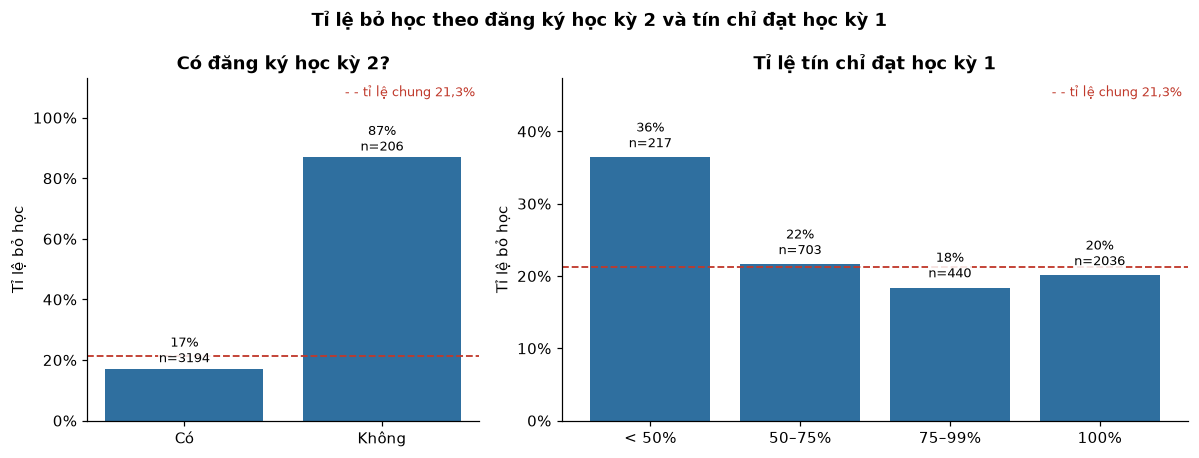

Hình 9 – Học kỳ 2: 206 sinh viên không đăng ký học kỳ 2 bỏ học 87%, so với 17% ở nhóm có đăng ký; nhóm này chiếm 25% tổng số sinh viên bỏ học.
Hình 9 – Tín chỉ đạt học kỳ 1: nhóm "< 50%" bỏ học 36% (n=217), cao gấp 2,0 lần nhóm "75–99%" (18%, n=440); tỉ lệ chung 21%.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
g9a = rate_by("has_second_term", "Có đăng ký học kỳ 2?", "", None, order=[1, 0], labels={1: "Có", 0: "Không"}, ax=axes[0])
df["earned_t1_grp"] = pd.cut(df["earned_ratio_t1"], [-0.01, 0.5, 0.75, 0.999, 1.0],
                             labels=["< 50%", "50–75%", "75–99%", "100%"])
g9b = rate_by("earned_t1_grp", "Tỉ lệ tín chỉ đạt học kỳ 1", "", None, order=["< 50%", "50–75%", "75–99%", "100%"],
              ax=axes[1])
fig.suptitle("Tỉ lệ bỏ học theo đăng ký học kỳ 2 và tín chỉ đạt học kỳ 1", fontweight="bold")
fig.tight_layout(); save(fig, "eda_09_hk2_tin_chi.png"); plt.show()
n_no = int((df["has_second_term"] == 0).sum())
s = (f"Hình 9 – Học kỳ 2: {n_no} sinh viên không đăng ký học kỳ 2 bỏ học {g9a.loc['Không', 'rate']:.0%}, "
     f"so với {g9a.loc['Có', 'rate']:.0%} ở nhóm có đăng ký; nhóm này chiếm "
     f"{df.loc[df['has_second_term'] == 0, 'dropout'].sum() / df['dropout'].sum():.0%} tổng số sinh viên bỏ học.")
CONCLUSIONS.append(s); print(s)
conclude(9, g9b, "Tín chỉ đạt học kỳ 1")

## Hình 10 – Tài chính
Trái: có/không có hồ sơ tài chính. Phải: phần tài chính thiếu hụt (chỉ sinh viên có hồ sơ), chia 4 nhóm.

Đã lưu eda_10_tai_chinh.png


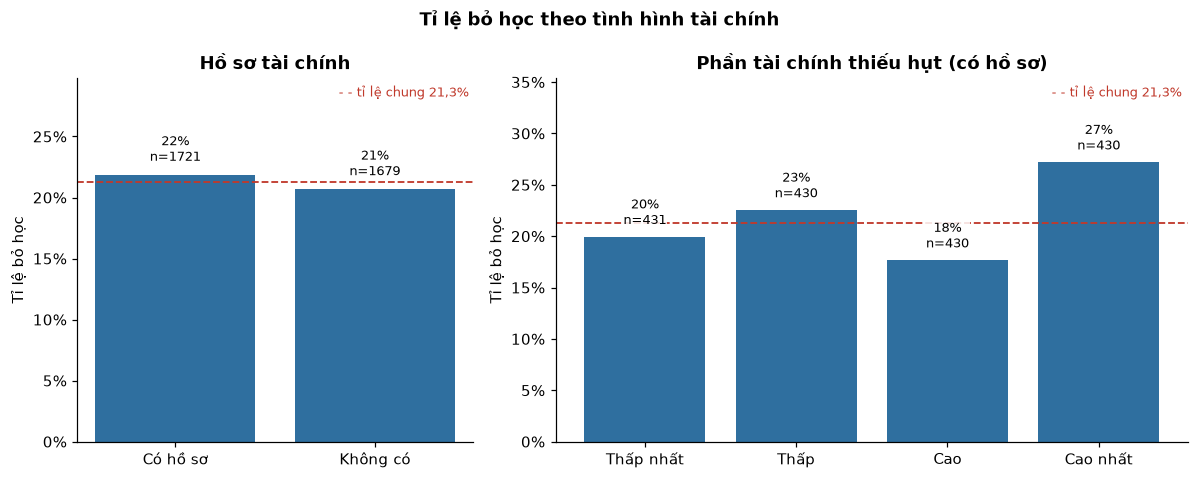

Hình 10 – Hồ sơ tài chính: nhóm "Có hồ sơ" bỏ học 22% (n=1721), cao gấp 1,1 lần nhóm "Không có" (21%, n=1679); tỉ lệ chung 21%.
Hình 10 – Phần thiếu hụt tài chính: nhóm "Cao nhất" bỏ học 27% (n=430), cao gấp 1,5 lần nhóm "Cao" (18%, n=430); tỉ lệ chung 21%.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})
g10a = rate_by("fin_data_missing", "Hồ sơ tài chính", "", None, order=[0, 1], labels={0: "Có hồ sơ", 1: "Không có"},
               ax=axes[0])
has = df["fin_data_missing"] == 0
q = pd.qcut(df.loc[has, "unmet_need"].rank(method="first"), 4, labels=["Thấp nhất", "Thấp", "Cao", "Cao nhất"])
df["unmet_grp"] = q.reindex(df.index).astype(object)
g10b = rate_by("unmet_grp", "Phần tài chính thiếu hụt (có hồ sơ)", "", None,
               order=["Thấp nhất", "Thấp", "Cao", "Cao nhất"], ax=axes[1])
fig.suptitle("Tỉ lệ bỏ học theo tình hình tài chính", fontweight="bold")
fig.tight_layout(); save(fig, "eda_10_tai_chinh.png"); plt.show()
conclude(10, g10a, "Hồ sơ tài chính")
conclude(10, g10b, "Phần thiếu hụt tài chính")

## Hình 11 – Tương quan giữa các yếu tố số
Dùng để giải thích vì sao vài feature có tầm ảnh hưởng chồng lấn (vd tín chỉ đạt và GPA).

Đã lưu eda_11_tuong_quan.png


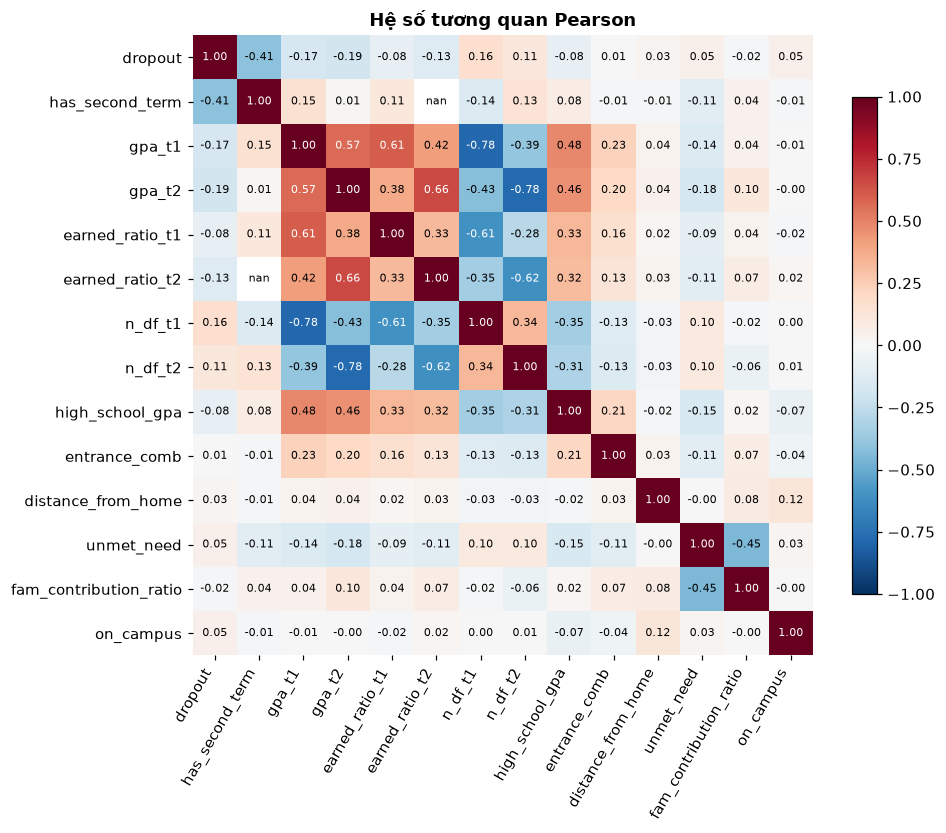

Hình 11 – Tương quan: 3 yếu tố tương quan mạnh nhất với bỏ học là has_second_term (-0.41), gpa_t2 (-0.19), gpa_t1 (-0.17).


In [13]:
cols = ["dropout", "has_second_term", "gpa_t1", "gpa_t2", "earned_ratio_t1", "earned_ratio_t2", "n_df_t1", "n_df_t2",
        "high_school_gpa", "entrance_comb", "distance_from_home", "unmet_need", "fam_contribution_ratio", "on_campus"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right"); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iat[i, j]) > 0.5 else "black")
fig.colorbar(im, shrink=0.8); ax.set_title("Hệ số tương quan Pearson")
ax.spines[:].set_visible(False)
fig.tight_layout(); save(fig, "eda_11_tuong_quan.png"); plt.show()
top = corr["dropout"].drop("dropout").abs().sort_values(ascending=False).head(3)
s = "Hình 11 – Tương quan: 3 yếu tố tương quan mạnh nhất với bỏ học là " + ", ".join(
    f"{c} ({corr.loc[c, 'dropout']:+.2f})" for c in top.index) + "."
CONCLUSIONS.append(s); print(s)

In [15]:
out = FIG / "eda_ket_luan.md"
out.write_text("# Kết luận EDA (tự sinh)\n\n" + "\n".join(f"- {s}" for s in CONCLUSIONS) + "\n",
               encoding="utf-8")
print(out.read_text(encoding="utf-8"))

# Kết luận EDA (tự sinh)

- Hình 1 – Theo khóa: tỉ lệ bỏ học dao động từ 16% đến 23% qua 6 khóa, quanh mức chung 21%.
- Hình 2 – Theo khoa: nhóm "Khoa học Xã hội & Nhân văn" bỏ học 24% (n=510), cao gấp 1,6 lần nhóm "Nghệ thuật" (15%, n=322); tỉ lệ chung 21%.
- Hình 3 – Nơi ở: nhóm "Ký túc xá" bỏ học 24% (n=1419), cao gấp 1,2 lần nhóm "Ở ngoài" (20%, n=1981); tỉ lệ chung 21%.
- Hình 3 – Trong/ngoài bang: nhóm "Ngoài bang" bỏ học 26% (n=337), cao gấp 1,3 lần nhóm "Trong bang" (21%, n=3063); tỉ lệ chung 21%.
- Hình 4 – Học vấn của bố: nhóm "THCS" bỏ học 27% (n=97), cao gấp 1,4 lần nhóm "Cao đẳng/Đại học trở lên" (20%, n=1309); tỉ lệ chung 21%.
- Hình 4 – Học vấn của mẹ: nhóm "Không có thông tin" bỏ học 25% (n=489), cao gấp 1,6 lần nhóm "Khác/Không rõ" (15%, n=117); tỉ lệ chung 21%.
- Hình 5 – GPA THPT: nhóm GPA thấp nhất (0,00–2,80) bỏ học 25%, nhóm cao nhất (3,64–4,00) chỉ 16% (chung 21%).
- Hình 6 – Điểm đầu vào: nhóm "Không có điểm" bỏ học 23% (n=518), cao gấp 1,2 lần nhóm "1110–1510" 